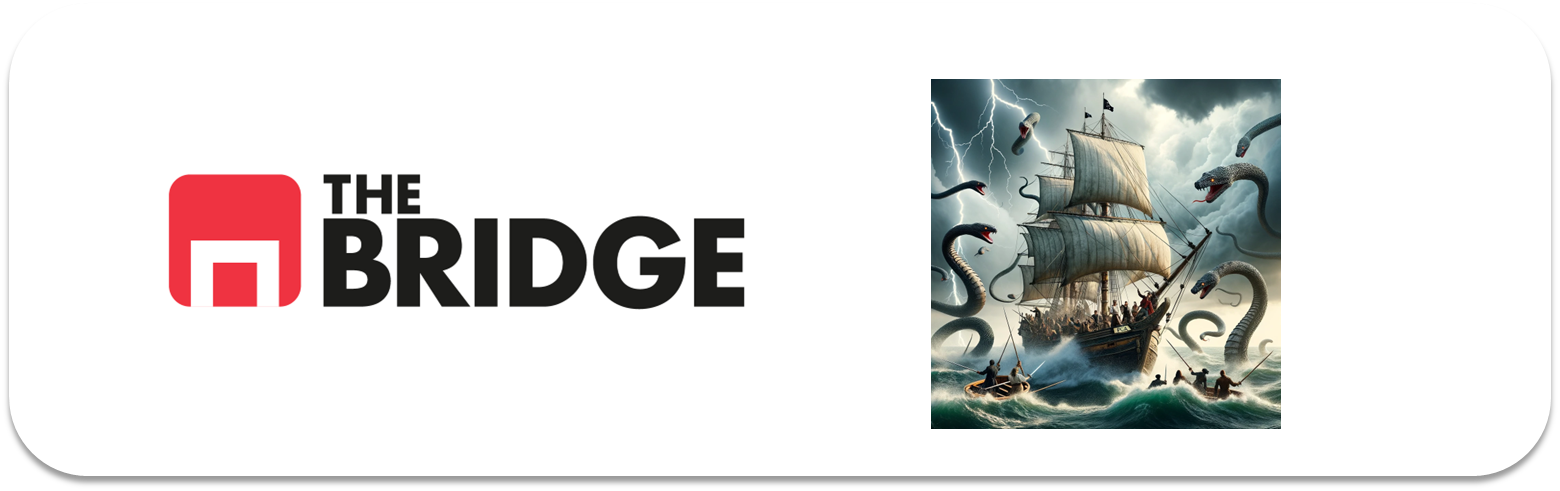

## PCA (I): Ejemplo de uso y obtención

### Carga de datos

Como siempre, empezamos importando y cargando las librerías necesarias.

In [1]:
# Tratamiento de datos
# ==============================================================================
import numpy as np
import pandas as pd

# Gráficos
# ==============================================================================
import matplotlib.pyplot as plt
plt.style.use('ggplot')

# Preprocesado y modelado
# ==============================================================================
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Configuración warnings
# ==============================================================================
import warnings
warnings.filterwarnings('ignore')

Para aprender a usar la PCA de sklearn vamos a utilizar un dataset clásico sobre criminalidad en EE. UU. (`USArrests`): para cada uno de los 50 estados recoge los arrestos por cada 100.000 habitantes por asesinato (`Murder`), agresión (`Assault`) y violación (`Rape`) en 1973, y el porcentaje de población urbana (`UrbanPop`). Lo tienes en el directorio `data` de la unidad.

In [2]:
# Dataset
datos = pd.read_csv("../data/USArrests.csv", index_col = "State")

Como siempre, hacemos nuestra primera revisión:

In [3]:
datos.info()

<class 'pandas.core.frame.DataFrame'>
Index: 50 entries, Alabama to Wyoming
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Murder    50 non-null     float64
 1   Assault   50 non-null     int64  
 2   UrbanPop  50 non-null     int64  
 3   Rape      50 non-null     float64
dtypes: float64(2), int64(2)
memory usage: 2.0+ KB


In [4]:
datos.head()

,Murder,Assault,UrbanPop,Rape
State,,,,
Alabama,13.2,236,58,21.2
Alaska,10.0,263,48,44.5
Arizona,8.1,294,80,31.0
Arkansas,8.8,190,50,19.5
California,9.0,276,91,40.6


In [5]:
print('----------------------')
print('Media de cada variable')
print('----------------------')
datos.mean(axis=0)

----------------------
Media de cada variable
----------------------


Murder        7.788
Assault     170.760
UrbanPop     65.540
Rape         21.232
dtype: float64

In [6]:
print('-------------------------')
print('Varianza de cada variable')
print('-------------------------')
datos.var(axis=0)

-------------------------
Varianza de cada variable
-------------------------


Murder        18.970465
Assault     6945.165714
UrbanPop     209.518776
Rape          87.729159
dtype: float64

Fíjate en que no fijamos un target, porque ahora no estamos buscando resolver un problema concreto, estamos buscando encontrar posibles features que contengan la misma información (en términos matemáticos) que el dataset original. Es por eso un aprendizaje no supervisado (vamos a "aprender" las componentes principales del dataset).

### Proceso de PCA

La obtención de la PCA sigue los siguientes pasos:  
1. Escalado de las variables  
2. Instanciación PCA   
3. "Entrenamiento"  
4. Mostrar valores PCA [No siempre es necesario] en función de las features iniciales
5. Análisis de la varianza explicada: Selección del número de componentes necesarias [Depende de la aplicación]  
6. Generación del dataset "PCAdo"


### Escalado PCA

Si no se estandarizan las variables para que tengan media cero y desviación estándar de uno antes de realizar el estudio PCA, la variable Assault, que tiene una media y dispersión muy superior al resto, dominará la mayoría de las componentes principales.

Veamos primero si alguna variable necesita una ayudita con una transformación.

array([[<Axes: title={'center': 'Murder'}>,
        <Axes: title={'center': 'Assault'}>],
       [<Axes: title={'center': 'UrbanPop'}>,
        <Axes: title={'center': 'Rape'}>]], dtype=object)

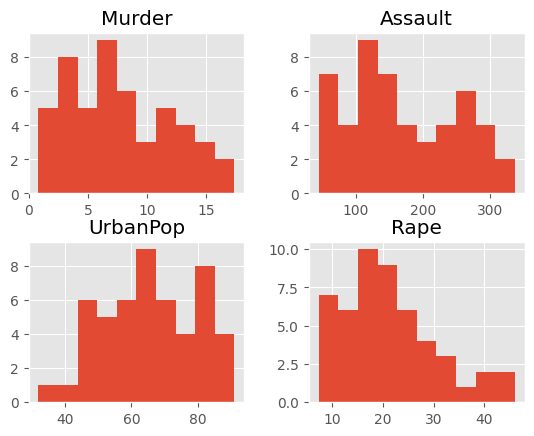

In [7]:
datos.hist()

*Ninguna variable presenta una asimetría fuerte (la más asimétrica, `Rape`, es moderada), así que no aplicamos transformaciones. Lo que sí es muy distinto es la escala: `Assault` está en cientos y `Murder` en unidades. Por eso escalamos:*

In [8]:
datos_sin = datos.copy()

In [9]:
scaler = StandardScaler()

datos[datos.columns.to_list()] = scaler.fit_transform(datos)

### Instanciación y entrenamiento

In [10]:
from sklearn.decomposition import PCA # Aquí es donde puedes encontrar la PCA

modelo_pca = PCA()
modelo_pca.fit(datos)

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",None
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized S

### Generamos la PCA y la ponemos en relación con las otras features

Para ver los coeficientes o parámetros aprendidos por el modelo PCA (los coeficientes de las componentes principales) usaremos el atributo `components_` del modelo:

In [11]:
modelo_pca.components_

array([[ 0.53589947,  0.58318363,  0.27819087,  0.54343209],
       [-0.41818087, -0.1879856 ,  0.87280619,  0.16731864],
       [-0.34123273, -0.26814843, -0.37801579,  0.81777791],
       [-0.6492278 ,  0.74340748, -0.13387773, -0.08902432]])

Pero veámoslo de una forma más entendible asociando cada coeficiente a su feature original:

In [12]:
# Se convierte el array a dataframe para añadir nombres a los ejes.
pd.DataFrame(
    data    = modelo_pca.components_, # En components_ están los autovectores, es decir, los coeficientes de la PCA
    columns = datos.columns,
    index   = ['PC1', 'PC2', 'PC3', 'PC4'] # En inglés pasamos de CP a PC :-) (Principal component)
)

,Murder,Assault,UrbanPop,Rape
PC1,0.535899,0.583184,0.278191,0.543432
PC2,-0.418181,-0.187986,0.872806,0.167319
PC3,-0.341233,-0.268148,-0.378016,0.817778
PC4,-0.649228,0.743407,-0.133878,-0.089024


Analizar con detalle el vector de loadings que forma cada componente puede ayudar a interpretar qué tipo de información recoge cada una de ellas. Por ejemplo, la primera componente es el resultado de la siguiente combinación lineal de las variables originales:

$PC1=0.535899*Murder+0.583184*Assault+0.278191*UrbanPop+0.543432*Rape$

Es decir, si queremos calcular la primera componente, iremos sustituyendo los valores de Murder, Assault, UrbanPop y Rape de cada instancia en la ecuación anterior y así la obtendremos.

La influencia de las variables en cada componente puede analizarse visualmente con un gráfico de tipo heatmap.

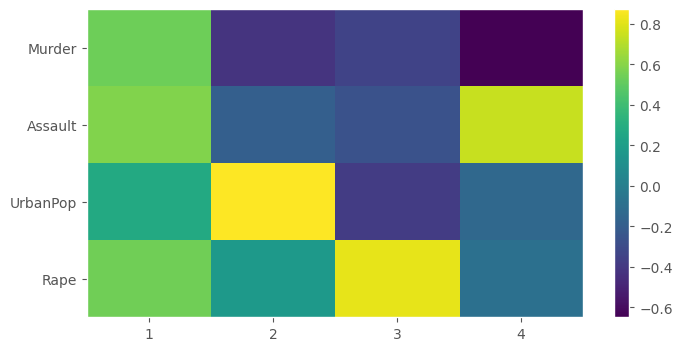

In [13]:
# Heatmap componentes
# ==============================================================================
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8, 4))
componentes = modelo_pca.components_
plt.imshow(componentes.T, cmap='viridis', aspect='auto')
plt.yticks(range(len(datos.columns)), datos.columns)
plt.xticks(range(len(datos.columns)), np.arange(modelo_pca.n_components_) + 1)
plt.grid(False)
plt.colorbar();

### Interpretación de las componentes

Mirando los loadings (la tabla y el heatmap) podemos ponerle "nombre" a las primeras componentes:

* **PC1**: los tres delitos (`Murder`, `Assault`, `Rape`) pesan casi lo mismo (≈0.54-0.58) y `UrbanPop` bastante menos (0.28). PC1 resume el **nivel general de criminalidad** del estado.
* **PC2**: la domina `UrbanPop` (0.87), con `Murder` en sentido contrario (-0.42). PC2 mide sobre todo el **grado de urbanización**.

NOTA: El signo de una componente es arbitrario (multiplicar todos los loadings por -1 da la misma componente). Si ves en otro libro o en otra versión de sklearn los mismos valores con el signo cambiado, es la misma componente: lo que importa es qué variables pesan juntas y cuáles en sentido contrario.

***

### Análisis de la varianza explicada

Como parte de la selección del número de componentes (nuevas features) con el que queremos quedarnos, es interesante ver el porcentaje de varianza (de capacidad informativa) de las nuevas features (de las componentes).

Para eso hacemos uso del atributo `explained_variance_ratio_` del modelo: 

In [14]:
modelo_pca.explained_variance_ratio_

array([0.62006039, 0.24744129, 0.0891408 , 0.04335752])

Ese es el porcentaje explicado por cada componente, y su suma debe ser igual a 1:


In [15]:
sum(modelo_pca.explained_variance_ratio_)

1.0000000000000002

La primera componente explica un 62% de la varianza, las dos primeras un 87%, etc. (y de esta forma escogeremos).  


NOTA importante: estamos explicando o "recogiendo" la varianza de los datos de partida, no necesariamente todas sus relaciones ni toda su potencia informativa (lo expresamos así para que se entienda mejor). En el ejemplo práctico de aplicación a modelos veremos que este porcentaje no quiere decir que, por ejemplo, un modelo entrenado solo con la primera componente principal (PC1) tenga un 62% del éxito del modelo con todas las features originales. Es solo orientativo.

Como en el caso de las componentes y coeficientes, veamos este ratio gráficamente:

----------------------------------------------------
Porcentaje de varianza explicada por cada componente
----------------------------------------------------
[0.62006039 0.24744129 0.0891408  0.04335752]


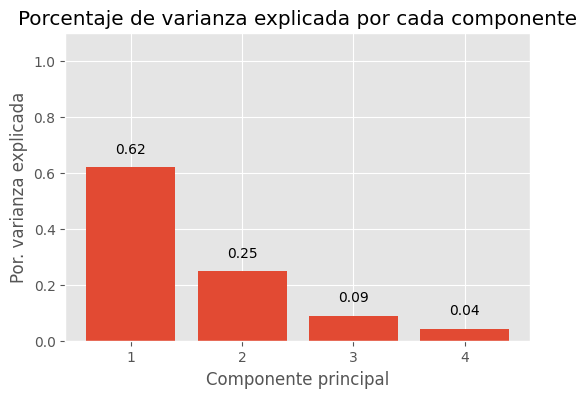

In [16]:
# Porcentaje de varianza explicada por cada componente
# ==============================================================================
print('----------------------------------------------------')
print('Porcentaje de varianza explicada por cada componente')
print('----------------------------------------------------')
print(modelo_pca.explained_variance_ratio_)

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(6, 4))
ax.bar(
    x      = np.arange(modelo_pca.n_components_) + 1,
    height = modelo_pca.explained_variance_ratio_
)

for x, y in zip(np.arange(len(datos.columns)) + 1, modelo_pca.explained_variance_ratio_):
    label = round(y, 2)
    ax.annotate(
        label,
        (x,y),
        textcoords="offset points",
        xytext=(0,10),
        ha='center'
    )

ax.set_xticks(np.arange(modelo_pca.n_components_) + 1)
ax.set_ylim(0, 1.1)
ax.set_title('Porcentaje de varianza explicada por cada componente')
ax.set_xlabel('Componente principal')
ax.set_ylabel('Por. varianza explicada');

Un gráfico que usaremos bastante para escoger el número de componentes con el que quedarnos es el de la varianza explicada acumulada. 

------------------------------------------
Porcentaje de varianza explicada acumulada
------------------------------------------
[0.62006039 0.86750168 0.95664248 1.        ]


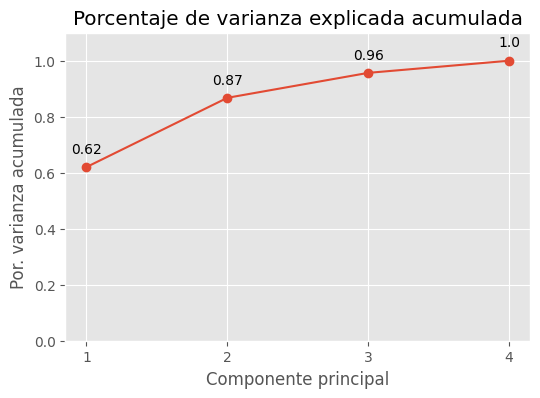

In [17]:
# Porcentaje de varianza explicada acumulada
# ==============================================================================
prop_varianza_acum = modelo_pca.explained_variance_ratio_.cumsum()
print('------------------------------------------')
print('Porcentaje de varianza explicada acumulada')
print('------------------------------------------')
print(prop_varianza_acum)

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(6, 4))
ax.plot(
    np.arange(len(datos.columns)) + 1,
    prop_varianza_acum,
    marker = 'o'
)

for x, y in zip(np.arange(len(datos.columns)) + 1, prop_varianza_acum):
    label = round(y, 2)
    ax.annotate(
        label,
        (x,y),
        textcoords="offset points",
        xytext=(0,10),
        ha='center'
    )
    
ax.set_ylim(0, 1.1)
ax.set_xticks(np.arange(modelo_pca.n_components_) + 1)
ax.set_title('Porcentaje de varianza explicada acumulada')
ax.set_xlabel('Componente principal')
ax.set_ylabel('Por. varianza acumulada');

Si se empleasen únicamente las dos primeras componentes se conseguiría explicar el 87% de la varianza observada. En el siguiente notebook veremos cómo escoger el número de componentes según el porcentaje de varianza que queramos conservar.

### Obtención del dataset con las "nuevas features"

Una vez entrenado el modelo, con el método `transform()` del modelo se puede reducir la dimensionalidad de nuevas observaciones proyectándolas en el espacio definido por las componentes. NOTA: Fíjate en que **NO es un método `predict`**, porque no se predice, sino que es la aplicación de una formulación exacta.

In [18]:
# Proyección de las observaciones de entrenamiento
# ==============================================================================
proyecciones = modelo_pca.transform(X=datos)
proyecciones = pd.DataFrame(
    proyecciones,
    columns = ['PC1', 'PC2', 'PC3', 'PC4'],
    index   = datos.index
)
proyecciones.head()

,PC1,PC2,PC3,PC4
State,,,,
Alabama,0.985566,-1.133392,-0.444269,-0.156267
Alaska,1.950138,-1.073213,2.040003,0.438583
Arizona,1.763164,0.745957,0.054781,0.834653
Arkansas,-0.141420,-1.119797,0.114574,0.182811
California,2.523980,1.542934,0.598557,0.341996


### Biplot: instancias y variables en el plano PC1-PC2

Con solo dos componentes recogemos el 87% de la varianza, así que podemos representar los 50 estados en un plano sin depender de mirar las features por parejas. Si además dibujamos los loadings de cada variable como flechas, obtenemos un **biplot**:

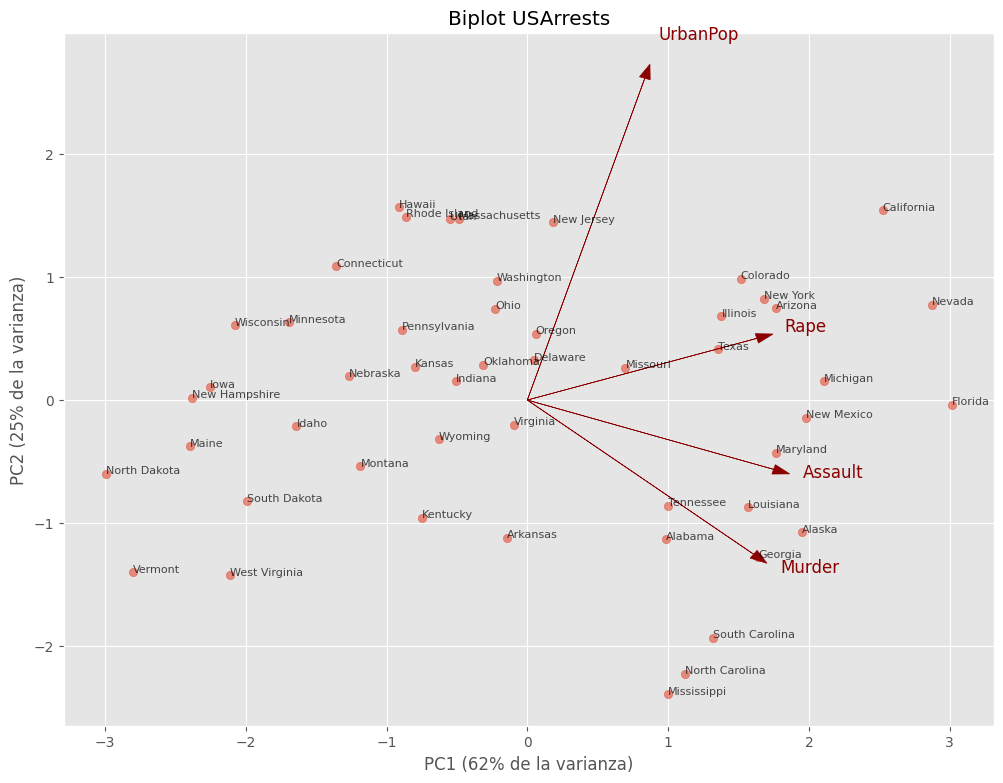

In [19]:
fig, ax = plt.subplots(figsize = (12, 9))
ax.scatter(proyecciones['PC1'], proyecciones['PC2'], alpha = 0.6)
for estado in proyecciones.index:
    ax.annotate(estado, (proyecciones.loc[estado, 'PC1'], proyecciones.loc[estado, 'PC2']), fontsize = 8, alpha = 0.7)

escala = 3 # Los loadings son menores que 1, los alargamos para que se vean junto a los puntos
for i, feature in enumerate(datos.columns):
    x, y = modelo_pca.components_[0, i] * escala, modelo_pca.components_[1, i] * escala
    ax.arrow(0, 0, x, y, color = 'darkred', head_width = 0.08)
    ax.text(x * 1.12, y * 1.12, feature, color = 'darkred', fontsize = 12)

ax.set_xlabel(f'PC1 ({modelo_pca.explained_variance_ratio_[0]:.0%} de la varianza)')
ax.set_ylabel(f'PC2 ({modelo_pca.explained_variance_ratio_[1]:.0%} de la varianza)')
ax.set_title('Biplot USArrests');

*Cómo se lee:*
* *Las flechas de los tres delitos apuntan hacia la derecha: los estados a la derecha (Florida, Nevada, California, Michigan) tienen más criminalidad; los de la izquierda (North Dakota, Vermont, Maine, New Hampshire), menos.*
* *La flecha de `UrbanPop` apunta hacia arriba: arriba están los estados más urbanos (Hawaii, California, Rhode Island, Massachusetts) y abajo los más rurales (Mississippi, North Carolina, South Carolina, West Virginia).*
* *Estados cercanos en el gráfico tienen perfiles parecidos. Esta forma de "ver" grupos de instancias en 2D es justo la que aprovecharemos en la unidad de Clustering.*

Podemos comprobar cómo la transformación es el resultado de multiplicar los vectores que definen cada componente por el valor de las variables. Puede calcularse de forma "manual", multiplicando los vectores de coeficientes por los vectores de las features:

In [20]:
modelo_pca.components_

array([[ 0.53589947,  0.58318363,  0.27819087,  0.54343209],
       [-0.41818087, -0.1879856 ,  0.87280619,  0.16731864],
       [-0.34123273, -0.26814843, -0.37801579,  0.81777791],
       [-0.6492278 ,  0.74340748, -0.13387773, -0.08902432]])

In [21]:
# components_ tiene forma (n_componentes, n_features). Para multiplicarla por todas las instancias transponemos los datos
# (número de columnas de A = número de filas de B, recuerdo de nuestros días de álgebra).
# transform() resta antes la media de cada feature (modelo_pca.mean_). Aquí es casi cero porque los datos están
# estandarizados, pero lo hacemos explícito para que el cálculo sea exactamente el mismo:
proyecciones = np.dot(modelo_pca.components_, (datos - modelo_pca.mean_).T)
proyecciones = pd.DataFrame(proyecciones, index = ['PC1', 'PC2', 'PC3', 'PC4']) 
proyecciones = proyecciones.transpose().set_index(datos.index) # Y luego transponer 
proyecciones.head()

,PC1,PC2,PC3,PC4
State,,,,
Alabama,0.985566,-1.133392,-0.444269,-0.156267
Alaska,1.950138,-1.073213,2.040003,0.438583
Arizona,1.763164,0.745957,0.054781,0.834653
Arkansas,-0.141420,-1.119797,0.114574,0.182811
California,2.523980,1.542934,0.598557,0.341996


Y puedes comprobar que da el mismo resultado. Además, a partir de los datos transformados es posible volver a los valores originales de las features (exactamente solo si usamos todas las componentes; con menos obtenemos una aproximación). Para ello usaremos el método `inverse_transform()` del modelo:

In [22]:
# Reconstrucción a partir de las proyecciones
# ==============================================================================
reconstruccion = modelo_pca.inverse_transform(X=proyecciones) # Así obtenemos el dataset de entrada que estaba escalado
datos_back = datos.copy()
datos_back[datos_sin.columns.to_list()] = scaler.inverse_transform(reconstruccion)
print('------------------')
print('Valores originales')
print('------------------')
display(datos_sin.head())

print('---------------------')
print('Valores reconstruidos')
print('---------------------')
display(datos_back.head())

------------------
Valores originales
------------------


,Murder,Assault,UrbanPop,Rape
State,,,,
Alabama,13.2,236,58,21.2
Alaska,10.0,263,48,44.5
Arizona,8.1,294,80,31.0
Arkansas,8.8,190,50,19.5
California,9.0,276,91,40.6


---------------------
Valores reconstruidos
---------------------


,Murder,Assault,UrbanPop,Rape
State,,,,
Alabama,13.2,236.0,58.0,21.2
Alaska,10.0,263.0,48.0,44.5
Arizona,8.1,294.0,80.0,31.0
Arkansas,8.8,190.0,50.0,19.5
California,9.0,276.0,91.0,40.6
